# Aulas IA Preditiva Modulo1 Semana 10 Aula2

### Clean Data

In [1]:
import unicodedata
import numpy as np
import pandas as pd

from script_functions import Visualizacao

class Analise:
    def __init__(self, dados):
        self.dados = dados

    def media_por(self, grupo, alvo="tempo_entrega_dias"):
        return self.dados.groupby(grupo)[alvo].agg(["count", "mean", "median"]).round(2)

class Graficos(Analise):
    
    # Distribuições
    def histograma(self, coluna, titulo, bins=30, limite=None):
        Visualizacao.histograma(self.dados, coluna, titulo, bins=bins, limite=limite)

    def boxplot(self, coluna, titulo, grupo=None, limite=None):
        Visualizacao.boxplot(self.dados, coluna, titulo, grupo=grupo, limite=limite)

    def comparar_histogramas(self, antes, depois, coluna, titulo_antes="Antes",
                             titulo_depois="Depois", bins=30, limite=None):
        Visualizacao.comparar_histogramas(antes, depois, coluna, titulo_antes, titulo_depois, bins, limite)

    def comparar_boxplots(self, antes, depois, coluna, titulo_antes="Antes",
                          titulo_depois="Depois", grupo=None, limite=None):
        Visualizacao.comparar_boxplots(antes, depois, coluna, titulo_antes, titulo_depois, grupo, limite)

    # Categorias e totais
    def barras_serie(self, serie, titulo, fmt="%.0f", horizontal=False, rotulo_valor="Quantidade"):
        Visualizacao.barras_serie(serie, titulo, fmt=fmt, horizontal=horizontal, rotulo_valor=rotulo_valor)

    def barras(self, categoria, valor, titulo, horizontal=False):
        Visualizacao.barras(self.dados, categoria, valor, titulo, horizontal=horizontal)

    def pizza(self, rotulo, valor, titulo=None):
        Visualizacao.pizza(self.dados, rotulo, valor, titulo)

    def mapa_calor(self, tabela, titulo, fmt="d"):
        Visualizacao.mapa_calor(tabela, titulo, fmt=fmt)

    def comparar_barras(self, antes, depois, titulo, rotulo_antes="Antes",
                        rotulo_depois="Depois", fmt="%.0f", horizontal=False):
        Visualizacao.comparar_barras(antes, depois, titulo, rotulo_antes, rotulo_depois, fmt, horizontal)

    # Relação entre duas colunas e linhas
    def dispersao(self, x, y, titulo, hue=None):
        Visualizacao.dispersao(self.dados, x, y, titulo, hue=hue)

    def linhas(self, x, y, titulo=None, marcador="o"):
        Visualizacao.linhas(self.dados, x, y, titulo, marcador=marcador)

    # Ausentes (usa os dados da instância)
    def mapa_ausentes(self, titulo, max_linhas=400):
        Visualizacao.mapa_ausentes(self.dados, titulo, max_linhas=max_linhas)

    def grafico_percentual_ausentes(self, titulo):
        Visualizacao.percentual_ausentes(self.dados, titulo)


In [2]:
class Limpeza(Graficos):
    def __init__(self, dados):
        self.dados = dados.copy()
        self.registro = []

    def registrar(self, passo, antes, depois):
        self.registro.append({"passo": passo, "antes": antes, "depois": depois})

    def relatorio(self):
        return pd.DataFrame(self.registro)

    def get_dados(self):
        return self.dados

In [3]:
pd.set_option("display.width", 120)
df_sujo = pd.read_csv("entregas_sujas.csv")
print(df_sujo.shape)

limpeza = Limpeza(df_sujo)

limpeza.get_dados().head(5)

(3000, 22)


,id_pedido,id_cliente,data_pedido,data_envio,data_entrega,estado,regiao,cidade,distancia_km,categoria_produto,...,quantidade_itens,valor_pedido,tipo_frete,transportadora,custo_frete,clima_envio,dia_semana_envio,fim_semana,dias_para_envio,tempo_entrega_dias
0,PED100147,CLI3792,2026-05-01,2026-05-04,2026-05-06,SP,Sudeste,São Paulo,48.8,Casa e cozinha,...,1.0,235.31,Padrão,CargaSul,20.88,Ensolarado,segunda,0,3,20.0
1,PED100936,CLI3680,2025-02-25,2025-02-27,2025-03-05,BA,Nordeste,Salvador,2254.0,Casa e cozinha,...,1.0,252.05,Padrão,Rápido Log,61.47,Ensolarado,quinta,0,2,6.0
2,PED100012,CLI2267,2026-01-05,2026-01-06,2026-01-15,PA,Norte,Belém,NaN,eletrônicos,...,1.0,375.63,Padrão,Log Nacional,57.80,Chuva,terça,0,1,9.0
3,PED102451,CLI1825,2025-01-31,2025-02-02,2025-02-10,PE,Nordeste,Recife,2495.3,Livros,...,1.0,62.45,Padrão,Rápido Log,78.98,Ensolarado,domingo,1,2,8.0
4,PED101056,CLI3045,2025-09-18,2025-09-20,2025-09-25,MG,Sudeste,Belo Horizonte,636.8,Roupas,...,2.0,195.68,Padrão,Rápido Log,26.53,Tempestade,sábado,1,2,5.0


### Tratamento de valores ausentes

Empty DataFrame
Columns: []
Index: []


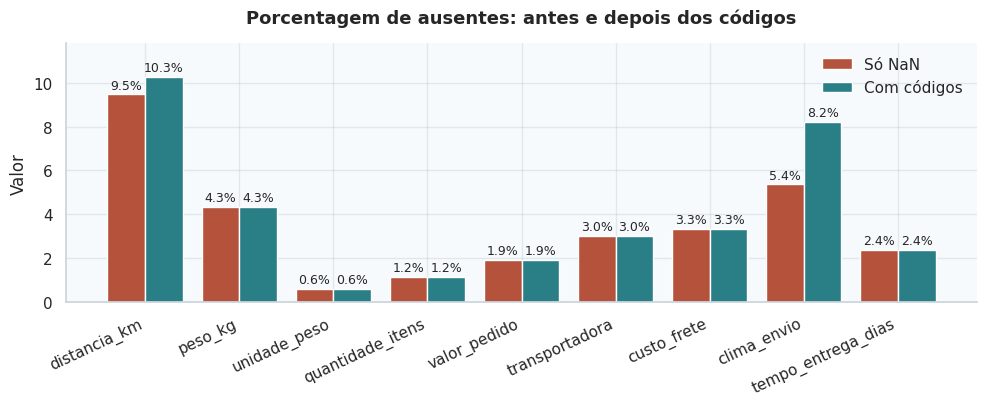

In [4]:
class TratadorAusentes(Limpeza):
    TOKENS = ["não informado", "--", -999]

    def percentual_ausentes(self):
        return (self.dados.isna().mean() * 100).round(1).sort_values(ascending=False)

    def converter_tokens(self):
        antes = int(self.dados.isna().sum().sum()) 
        # tratando os ausentes
        self.dados = self.dados.replace(self.TOKENS, np.nan)
        self.registrar("códigos de ausência -> NaN", antes, int(self.dados.isna().sum().sum()))

    def percentual_por_grupo(self, coluna, grupo):
        return self.dados.groupby(grupo)[coluna].apply(lambda s: s.isna().mean() * 100).round(1)

limpeza_ausente = TratadorAusentes(limpeza.dados)

''' # self.dados.isna().sum()
id_pedido	10
id_cliente	5
data_pedido	5
data_envio	0
data_entrega 10	

self.dados.isna().sum().sum()
30
'''

ausentes_antes = df_sujo.isna().mean().mul(100)
limpeza_ausente.converter_tokens() # ["não informado", "--", -999] -> NaN
print(limpeza.relatorio())
ausentes_depois = limpeza_ausente.dados.isna().mean().mul(100)
colunas = ausentes_depois[ausentes_depois > 0].index

limpeza_ausente.comparar_barras(ausentes_antes[colunas], ausentes_depois[colunas],\
                         "Porcentagem de ausentes: antes e depois dos códigos",\
                         "Só NaN", "Com códigos", fmt="%.1f%%")
# Saída:
#                         passo  antes  depois
# 0  códigos de ausência -> NaN    948    1057



In [5]:
print(limpeza_ausente.percentual_ausentes())

distancia_km          10.3
clima_envio            8.2
peso_kg                4.3
custo_frete            3.3
transportadora         3.0
tempo_entrega_dias     2.4
valor_pedido           1.9
quantidade_itens       1.2
unidade_peso           0.6
categoria_produto      0.0
cidade                 0.0
id_cliente             0.0
regiao                 0.0
estado                 0.0
tipo_frete             0.0
data_entrega           0.0
data_envio             0.0
data_pedido            0.0
dia_semana_envio       0.0
fim_semana             0.0
dias_para_envio        0.0
id_pedido              0.0
dtype: float64


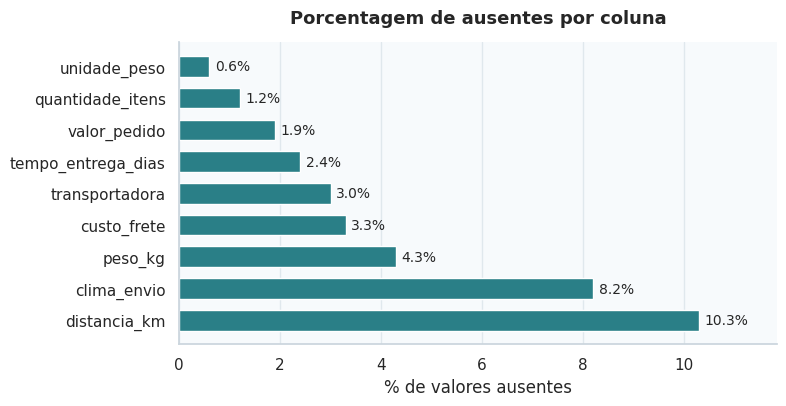

In [6]:
limpeza_ausente.grafico_percentual_ausentes("Porcentagem de ausentes por coluna")

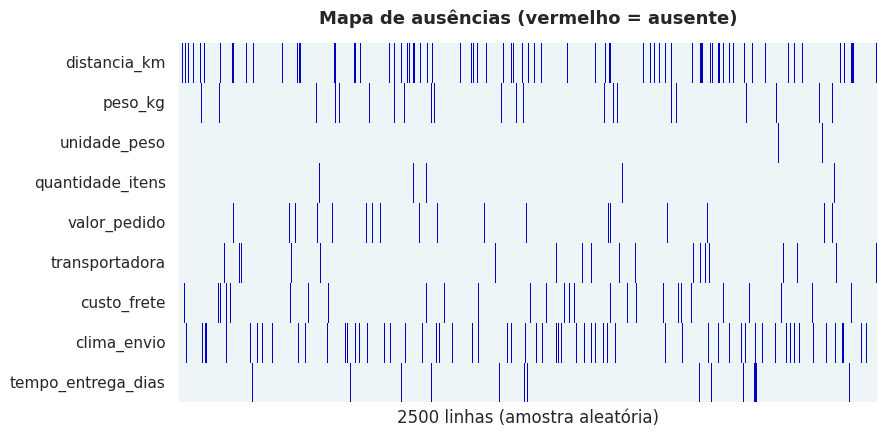

In [8]:
limpeza_ausente.mapa_ausentes("Mapa de ausências (vermelho = ausente)", max_linhas=2500)

### Tratamento de normalizar texto

In [13]:
class TratadorTexto(TratadorAusentes):
    @staticmethod
    def chave(texto):
        sem_acento = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode()
        return sem_acento.lower().replace(" ", "")

    def padronizar_categorias(self, coluna, valores):
        mapa = {self.chave(v): v for v in valores}
        antes = self.dados[coluna].nunique()
        self.dados[coluna] = self.dados[coluna].map(
            lambda t: mapa.get(self.chave(t), t) if isinstance(t, str) else t)
        self.registrar(f"{coluna}: categorias padronizadas", antes, self.dados[coluna].nunique())

limpeza_texto = TratadorTexto(limpeza_ausente.dados)

VALORES = {
    "estado": ["AM", "BA", "CE", "DF", "GO", "MG", "PA", "PE", "PR", "RJ", "RS", "SC", "SP"],
    "regiao": ["Centro-Oeste", "Nordeste", "Norte", "Sudeste", "Sul"],
    "tipo_frete": ["Econômico", "Expresso", "Padrão"],
    "transportadora": ["CargaSul", "Entrega Ágil", "Log Nacional", "Rápido Log"],
    "categoria_produto": ["Brinquedos", "Casa e cozinha", "Eletrônicos", "Ferramentas", "Livros", "Roupas"],
}
for coluna, valores in VALORES.items():
    limpeza_texto.padronizar_categorias(coluna, valores)

print(limpeza_texto.relatorio().tail(5))



                                        passo  antes  depois
0             estado: categorias padronizadas     52      13
1             regiao: categorias padronizadas     15       5
2         tipo_frete: categorias padronizadas     12       3
3     transportadora: categorias padronizadas     15       4
4  categoria_produto: categorias padronizadas     12       6


regiao
Sudeste         1251
Sul              589
Nordeste         585
Norte            266
Centro-Oeste     173
sudeste           33
SUDESTE           23
sul               17
SUL               17
nordeste          16
NORDESTE          13
norte              9
NORTE              4
CENTRO-OESTE       2
centro-oeste       2
Name: count, dtype: int64
--------
regiao
Sudeste         1307
Sul              623
Nordeste         614
Norte            279
Centro-Oeste     177
Name: count, dtype: int64


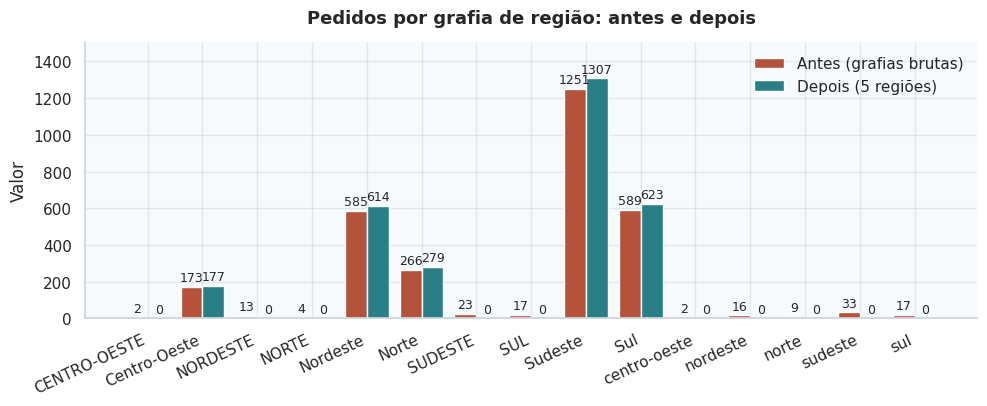

In [19]:
regiao_antes = df_sujo["regiao"].value_counts()
print(regiao_antes)
print("--------")
regiao_depois = limpeza_texto.dados["regiao"].value_counts()
print(regiao_depois)
limpeza_texto.comparar_barras(regiao_antes, regiao_depois,\
 "Pedidos por grafia de região: antes e depois",\
 "Antes (grafias brutas)", "Depois (5 regiões)", fmt="%.0f")

### Tratamento de valores monetarios (tipo)

categoria_produto
Brinquedos        411
Casa e cozinha    490
Eletrônicos       600
Ferramentas       409
Livros            233
Name: valor_pedido, dtype: int64
---------
count     2942.00
mean       587.82
std       1680.52
min         16.50
25%        132.31
50%        249.51
75%        567.53
max      65467.00
Name: valor_pedido, dtype: float64
---------
categoria_produto
Brinquedos        419
Casa e cozinha    520
Eletrônicos       627
Ferramentas       427
Livros            252
Name: valor_pedido, dtype: int64 12


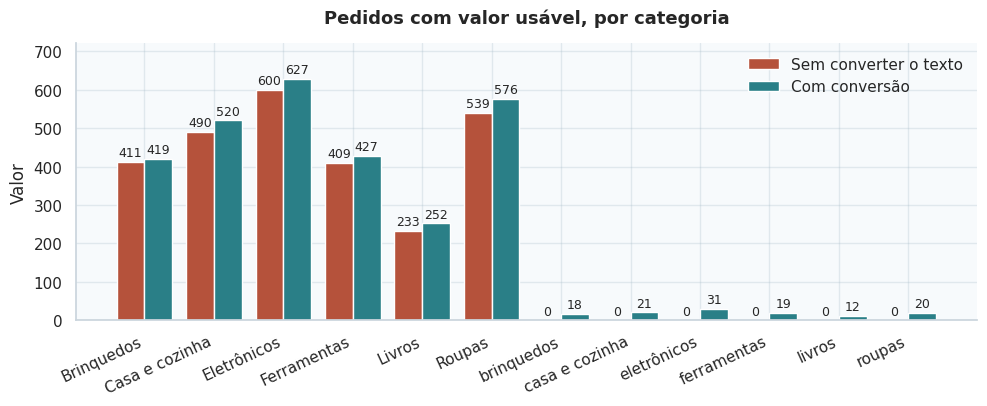

In [ ]:
class TratadorTipos(TratadorTexto):
    @staticmethod
    def _moeda(valor):
        if isinstance(valor, str):
            texto = valor.replace("R$", "").strip()
            if "," in texto:  # formato brasileiro: 1.250,50 (ponto separa milhar, vírgula é decimal) -> 1250.50
                texto = texto.replace(".", "").replace(",", ".")
            return float(texto)  # sem vírgula: já está em formato 1250.50
        return valor

    def converter_moeda(self, coluna):
        textos = int(self.dados[coluna].map(lambda v: isinstance(v, str)).sum())
        self.dados[coluna] = pd.to_numeric(self.dados[coluna].map(self._moeda))
        self.registrar(f"{coluna}: texto -> número", textos, 0)

    def converter_datas(self, colunas):
        for coluna in colunas:
            textos = int(self.dados[coluna].map(lambda v: isinstance(v, str)).sum())
            self.dados[coluna] = pd.to_datetime(self.dados[coluna], format="mixed", dayfirst=True)
            self.registrar(f"{coluna}: texto -> data", textos, 0)
            

com_valor_antes = (pd.to_numeric(limpeza_texto.dados["valor_pedido"], errors="coerce")
                   .groupby(limpeza_texto.dados["categoria_produto"]).count())

print(com_valor_antes[:5])

limpeza_tipo = TratadorTipos(limpeza_texto.dados)
limpeza_tipo.converter_moeda("valor_pedido")
print("---------")
print(limpeza_tipo.dados["valor_pedido"].describe().round(2))
com_valor_depois = limpeza_tipo.dados["valor_pedido"].groupby(limpeza.dados["categoria_produto"]).count()
print("---------")
print(com_valor_depois[:5], len(com_valor_depois))

limpeza_tipo.comparar_barras(com_valor_antes, com_valor_depois, "Pedidos com valor usável, por categoria",\
    "Sem converter o texto", "Com conversão", fmt="%.0f")



data_pedido
2025Q1    500
2025Q2    496
2025Q3    537
2025Q4    501
2026Q1    464
2026Q2    502
Freq: Q-DEC, Name: count, dtype: int64
  data_pedido data_envio data_entrega
0  2026-05-01 2026-05-04   2026-05-06
1  2025-02-25 2025-02-27   2025-03-05
2  2026-01-05 2026-01-06   2026-01-15
-------
data_pedido
2025Q1    500
2025Q2    496
2025Q3    537
2025Q4    501
2026Q1    464
2026Q2    502
Freq: Q-DEC, Name: count, dtype: int64


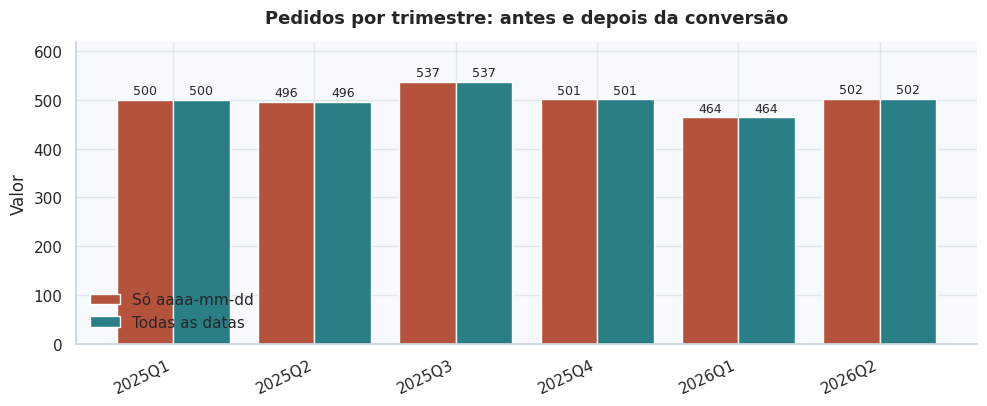

In [37]:
por_trimestre_antes = (pd.to_datetime(limpeza_tipo.dados["data_pedido"], format="%Y-%m-%d", errors="coerce")\
                       .dt.to_period("Q").value_counts().sort_index())

print(por_trimestre_antes)

limpeza_tipo.converter_datas(["data_pedido", "data_envio", "data_entrega"])
print(limpeza_tipo.dados[["data_pedido", "data_envio", "data_entrega"]].head(3))

print("-------")
por_trimestre_depois = limpeza_tipo.dados["data_pedido"].dt.to_period("Q").value_counts().sort_index()
print(por_trimestre_depois)
limpeza_tipo.comparar_barras(por_trimestre_antes, por_trimestre_depois, \
                        "Pedidos por trimestre: antes e depois da conversão",\
                         "Só aaaa-mm-dd", "Todas as datas", fmt="%.0f")
